In [1]:
import os
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
from torchvision import datasets, models, transforms
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score

In [2]:
def seed():
    random.seed(42)
    np.random.seed(42)
    torch.manual_seed(42)
    torch.cuda.manual_seed_all(42)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

In [3]:
import torch

print("Versi PyTorch:", torch.__version__)
print("Versi CUDA PyTorch:", torch.version.cuda)
print("GPU terdeteksi:", torch.cuda.is_available())

!nvidia-smi

Versi PyTorch: 2.11.0+cu130
Versi CUDA PyTorch: 13.0
GPU terdeteksi: True
Mon Oct 12 12:13:37 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   39C    P8             15W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                       

In [4]:
seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
weights = models.ResNet18_Weights.IMAGENET1K_V1
loss_fn = nn.CrossEntropyLoss()
os.makedirs("hasil", exist_ok=True)

if not torch.cuda.is_available():
    raise RuntimeError("GPU belum aktif. Pilih GPU di pengaturan Colab.")

device = torch.device("cuda")

print("GPU:", torch.cuda.get_device_name(0))
print(device)

GPU: Tesla T4
cuda


In [5]:
breeds = [
    "Abyssinian", "Bengal", "Birman", "British_Shorthair", "Siamese",
    "beagle", "boxer", "chihuahua", "pug", "samoyed"
]

datasets.OxfordIIITPet("data", split="trainval", download=True)
datasets.OxfordIIITPet("data", split="test", download=True)

tables = []

for split in ["trainval", "test"]:
    file = f"data/oxford-iiit-pet/annotations/{split}.txt"

    table = pd.read_csv(
        file,
        sep=r"\s+",
        names=["id", "old_label", "species", "species_label"],
        comment="#"
    )

    tables.append(table)

data = pd.concat(tables, ignore_index=True)

data["breed"] = data["id"].str.rsplit("_", n=1).str[0]
data = data[data["breed"].isin(breeds)]
data = data.sort_values("id")
data = data.reset_index(drop=True)

data["label"] = data["breed"].apply(breeds.index)
data["path"] = "data/oxford-iiit-pet/images/" + data["id"] + ".jpg"

assert data["id"].is_unique
assert set(data["breed"]) == set(breeds)

train, rest = train_test_split(
    data,
    test_size=0.3,
    stratify=data["label"],
    random_state=42
)

val, test = train_test_split(
    rest,
    test_size=0.5,
    stratify=rest["label"],
    random_state=42
)

assert set(train.index).isdisjoint(val.index)
assert set(train.index).isdisjoint(test.index)
assert set(val.index).isdisjoint(test.index)

split_table = pd.concat([
    train.assign(split="train"),
    val.assign(split="val"),
    test.assign(split="test")
])

split_table.to_csv("hasil/split.csv", index=False)

counts = pd.crosstab(split_table["breed"], split_table["split"])
print(counts.reindex(breeds))

100%|██████████| 792M/792M [00:30<00:00, 26.1MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 10.0MB/s]


split              test  train  val
breed                              
Abyssinian           30    139   29
Bengal               30    140   30
Birman               30    140   30
British_Shorthair    30    140   30
Siamese              30    139   30
beagle               30    140   30
boxer                30    139   30
chihuahua            30    140   30
pug                  30    140   30
samoyed              30    140   30


In [6]:
eval_transform = weights.transforms()
mean = eval_transform.mean
std = eval_transform.std

train_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])


class PetData(Dataset):
    def __init__(self, table, transform):
        self.table = table.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.table)

    def __getitem__(self, index):
        row = self.table.iloc[index]

        with Image.open(row["path"]) as image:
            image = image.convert("RGB")
            image = self.transform(image)

        label = int(row["label"])
        return image, label


def loader(table, transform, shuffle=False):
    dataset = PetData(table, transform)

    generator = torch.Generator()
    generator.manual_seed(42)

    return DataLoader(
        dataset,
        batch_size=32,
        shuffle=shuffle,
        generator=generator
    )


val_loader = loader(val, eval_transform)
test_loader = loader(test, eval_transform)
clean_loader = loader(train, eval_transform)

In [7]:
def evaluate(model, data_loader):
    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    actual = []
    predicted = []
    confidence = []

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device)

            output = model(images)
            loss = loss_fn(output, labels)

            probabilities = torch.softmax(output, dim=1)
            prob, guess = probabilities.max(dim=1)

            batch_size = len(labels)
            total_loss += loss.item() * batch_size
            correct += (guess == labels).sum().item()
            total += batch_size

            actual.extend(labels.cpu().tolist())
            predicted.extend(guess.cpu().tolist())
            confidence.extend(prob.cpu().tolist())

    average_loss = total_loss / total
    accuracy = correct / total

    return average_loss, accuracy, actual, predicted, confidence

In [12]:
if not torch.cuda.is_available():
    raise RuntimeError("GPU belum aktif.")

device = torch.device("cuda")

trained = {}
results = []

for name in ["B1", "B2", "B3", "B4_noaug", "B5"]:
    seed()
    strategy = name

    # Buat model baru untuk setiap eksperimen
    if name == "B5":
        source = results[0]

        for result in results:
            if result["val_loss"] < source["val_loss"]:
                source = result

        strategy = source["run"]
        print("B5 mengikuti konfigurasi:", strategy)

        if strategy == "B1":
            model = models.efficientnet_b0(weights=None)
        else:
            model = models.efficientnet_b0(
                weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1
            )

    elif name == "B1":
        model = models.resnet18(weights=None)

    else:
        model = models.resnet18(weights=weights)

    if strategy != "B1":
        for param in model.parameters():
            param.requires_grad = False

    torch.manual_seed(42)

    if name == "B5":
        num_features = model.classifier[1].in_features
        model.classifier[1] = nn.Linear(num_features, 10)

        head = model.classifier
        tail = model.features[7:]

    else:
        model.fc = nn.Linear(model.fc.in_features, 10)

        head = model.fc
        tail = model.layer4

    if strategy == "B3":
        for param in tail.parameters():
            param.requires_grad = True

    model = model.to(device)

    active = 0
    total_params = 0

    for param in model.parameters():
        total_params += param.numel()

        if param.requires_grad:
            active += param.numel()

    print(name, "trainable parameters:", active)

    # Tentukan parameter yang masuk optimizer
    if strategy == "B1":
        optimizer = torch.optim.AdamW(
            model.parameters(),
            lr=1e-3,
            weight_decay=1e-2
        )

    elif strategy == "B3":
        optimizer = torch.optim.AdamW([
            {"params": tail.parameters(), "lr": 1e-4},
            {"params": head.parameters(), "lr": 1e-3}
        ], weight_decay=1e-2)

    else:
        optimizer = torch.optim.AdamW(
            head.parameters(),
            lr=1e-3,
            weight_decay=1e-2
        )

    rates = []
    for group in optimizer.param_groups:
        rates.append(group["lr"])

    if strategy == "B4_noaug":
        train_loader = loader(train, eval_transform, shuffle=True)
    else:
        train_loader = loader(train, train_transform, shuffle=True)

    best_loss = float("inf")
    best_epoch = 0
    waiting = 0
    history = []
    checkpoint = f"hasil/{name}.pt"

    torch.cuda.synchronize()
    start = time.perf_counter()

    for epoch in range(1, 26):
        model.train()

        # Pertahankan statistik BatchNorm pretrained
        if strategy != "B1":
            if name == "B5":
                model.features.eval()

                if strategy == "B3":
                    tail.train()

            for layer in model.modules():
                if isinstance(layer, nn.BatchNorm2d):
                    layer.eval()

        total_loss = 0.0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            output = model(images)
            loss = loss_fn(output, labels)

            if not torch.isfinite(loss):
                raise ValueError("Loss tidak valid.")

            loss.backward()
            optimizer.step()

            total_loss += loss.item() * len(labels)

        train_loss = total_loss / len(train)

        validation = evaluate(model, val_loader)
        val_loss = validation[0]
        val_acc = validation[1]

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "val_acc": val_acc,
            "params": active,
            "lr": rates
        })

        history_table = pd.DataFrame(history)
        history_table.to_csv(
            f"hasil/{name}_history.csv",
            index=False
        )

        print(
            name,
            "epoch", epoch,
            "validation loss:", round(val_loss, 4)
        )

        if val_loss < best_loss:
            best_loss = val_loss
            best_epoch = epoch
            waiting = 0

            torch.save(model.state_dict(), checkpoint)
        else:
            waiting += 1

        if waiting >= 4:
            break

    torch.cuda.synchronize()
    seconds = time.perf_counter() - start

    # Gunakan checkpoint terbaik untuk evaluasi akhir
    best_weights = torch.load(
        checkpoint,
        map_location=device,
        weights_only=True
    )
    model.load_state_dict(best_weights)

    train_evaluation = evaluate(model, clean_loader)
    train_acc = train_evaluation[1]

    validation = evaluate(model, val_loader)
    val_loss = validation[0]
    val_acc = validation[1]

    results.append({
        "run": name,
        "strategy": strategy,
        "params": active,
        "total_params": total_params,
        "lr": rates,
        "best_epoch": best_epoch,
        "epochs_run": epoch,
        "seconds": seconds,
        "val_loss": val_loss,
        "val_acc": val_acc,
        "train_acc": train_acc,
        "gap_pp": 100 * (train_acc - val_acc)
    })

    trained[name] = model.cpu()

# Pilih model menggunakan validation loss
best_name = results[0]["run"]
lowest_loss = results[0]["val_loss"]

for result in results:
    if result["val_loss"] < lowest_loss:
        lowest_loss = result["val_loss"]
        best_name = result["run"]

validation_table = pd.DataFrame(results)
validation_table.to_csv("hasil/validation.csv", index=False)

selection = pd.DataFrame([{
    "best_run": best_name,
    "criterion": "validation loss"
}])
selection.to_csv("hasil/selection.csv", index=False)

print("Model terpilih sebelum test:", best_name)

B1 trainable parameters: 11181642
B1 epoch 1 validation loss: 2.7686
B1 epoch 2 validation loss: 2.2359
B1 epoch 3 validation loss: 2.3606
B1 epoch 4 validation loss: 2.4994
B1 epoch 5 validation loss: 3.677
B1 epoch 6 validation loss: 1.7162
B1 epoch 7 validation loss: 1.7339
B1 epoch 8 validation loss: 1.8034
B1 epoch 9 validation loss: 2.3652
B1 epoch 10 validation loss: 1.571
B1 epoch 11 validation loss: 1.8778
B1 epoch 12 validation loss: 1.4785
B1 epoch 13 validation loss: 2.2361
B1 epoch 14 validation loss: 1.5113
B1 epoch 15 validation loss: 1.7592
B1 epoch 16 validation loss: 1.4455
B1 epoch 17 validation loss: 1.6034
B1 epoch 18 validation loss: 3.0661
B1 epoch 19 validation loss: 1.5525
B1 epoch 20 validation loss: 1.9963
B2 trainable parameters: 5130
B2 epoch 1 validation loss: 0.5521
B2 epoch 2 validation loss: 0.3003
B2 epoch 3 validation loss: 0.2506
B2 epoch 4 validation loss: 0.2159
B2 epoch 5 validation loss: 0.1818
B2 epoch 6 validation loss: 0.173
B2 epoch 7 validat

In [13]:
predictions = {}

for row in results:
    name = row["run"]
    model = trained[name].to(device)

    evaluation = evaluate(model, test_loader)
    accuracy = evaluation[1]
    actual = evaluation[2]
    predicted = evaluation[3]
    confidence = evaluation[4]

    macro_f1 = f1_score(
        actual,
        predicted,
        labels=list(range(10)),
        average="macro",
        zero_division=0
    )

    row["test_acc"] = accuracy
    row["test_f1"] = macro_f1

    actual_names = []
    for label in actual:
        actual_names.append(breeds[label])

    predicted_names = []
    for label in predicted:
        predicted_names.append(breeds[label])

    table = test[["id", "path"]].copy()
    table = table.reset_index(drop=True)

    table["actual"] = actual_names
    table["predicted"] = predicted_names
    table["confidence"] = confidence

    table.to_csv(
        f"hasil/{name}_predictions.csv",
        index=False
    )

    predictions[name] = table
    model.cpu()

metrics = pd.DataFrame(results)
metrics.to_csv("hasil/metrics.csv", index=False)

print("Hasil B1 sampai B5:")
display(metrics)

print("Perbandingan augmentasi:")
augmentation_results = metrics[
    metrics["run"].isin(["B2", "B4_noaug"])
]
display(augmentation_results)

print("Perbandingan arsitektur B5:")

b5_result = metrics[metrics["run"] == "B5"]
source_name = b5_result.iloc[0]["strategy"]

architecture_results = metrics[
    metrics["run"].isin([source_name, "B5"])
]

architecture_results = architecture_results[[
    "run",
    "params",
    "total_params",
    "seconds",
    "val_acc",
    "test_f1"
]]

display(architecture_results)

architecture_results.to_csv(
    "hasil/architecture_comparison.csv",
    index=False
)

Hasil B1 sampai B5:


,run,strategy,params,total_params,lr,best_epoch,epochs_run,seconds,val_loss,val_acc,train_acc,gap_pp,test_acc,test_f1
0,B1,B1,11181642,11181642,[0.001],16,20,405.410629,1.445550,0.518395,0.574803,5.640850,0.520000,0.507617
1,B2,B2,5130,11181642,[0.001],15,19,324.552030,0.132812,0.956522,0.978525,2.200367,0.976667,0.976668
2,B3,B3,8398858,11181642,"[0.0001, 0.001]",9,13,227.115724,0.121267,0.959866,0.993558,3.369140,0.986667,0.986652
3,B4_noaug,B4_noaug,5130,11181642,[0.001],16,20,244.837185,0.119115,0.956522,0.995705,3.918334,0.973333,0.973273
4,B5,B4_noaug,12810,4020358,[0.001],24,25,328.087956,0.056868,0.979933,1.000000,2.006689,0.986667,0.986661


Perbandingan augmentasi:


,run,strategy,params,total_params,lr,best_epoch,epochs_run,seconds,val_loss,val_acc,train_acc,gap_pp,test_acc,test_f1
1,B2,B2,5130,11181642,[0.001],15,19,324.552030,0.132812,0.956522,0.978525,2.200367,0.976667,0.976668
3,B4_noaug,B4_noaug,5130,11181642,[0.001],16,20,244.837185,0.119115,0.956522,0.995705,3.918334,0.973333,0.973273


Perbandingan arsitektur B5:


,run,params,total_params,seconds,val_acc,test_f1
3,B4_noaug,5130,11181642,244.837185,0.956522,0.973273
4,B5,12810,4020358,328.087956,0.979933,0.986661


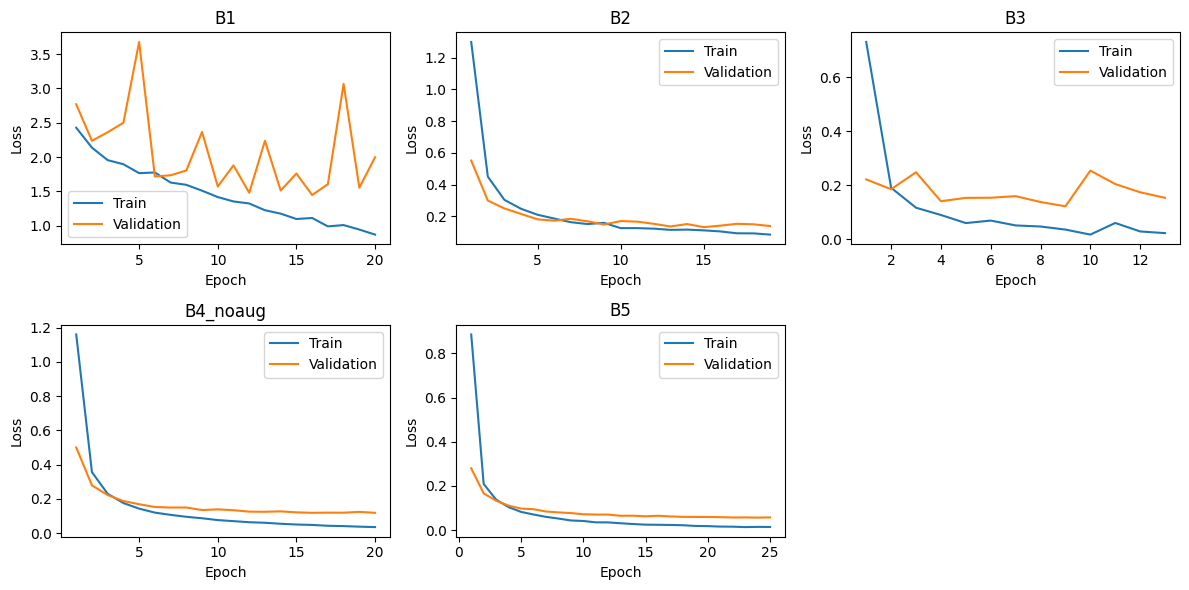

Failure analysis model: B5


,id,actual,predicted,confidence,hipotesis
280,Bengal_84,Bengal,Abyssinian,0.853797,
281,Birman_124,Birman,Siamese,0.755705,
242,Siamese_150,Siamese,Abyssinian,0.728806,
195,Siamese_228,Siamese,Birman,0.559195,


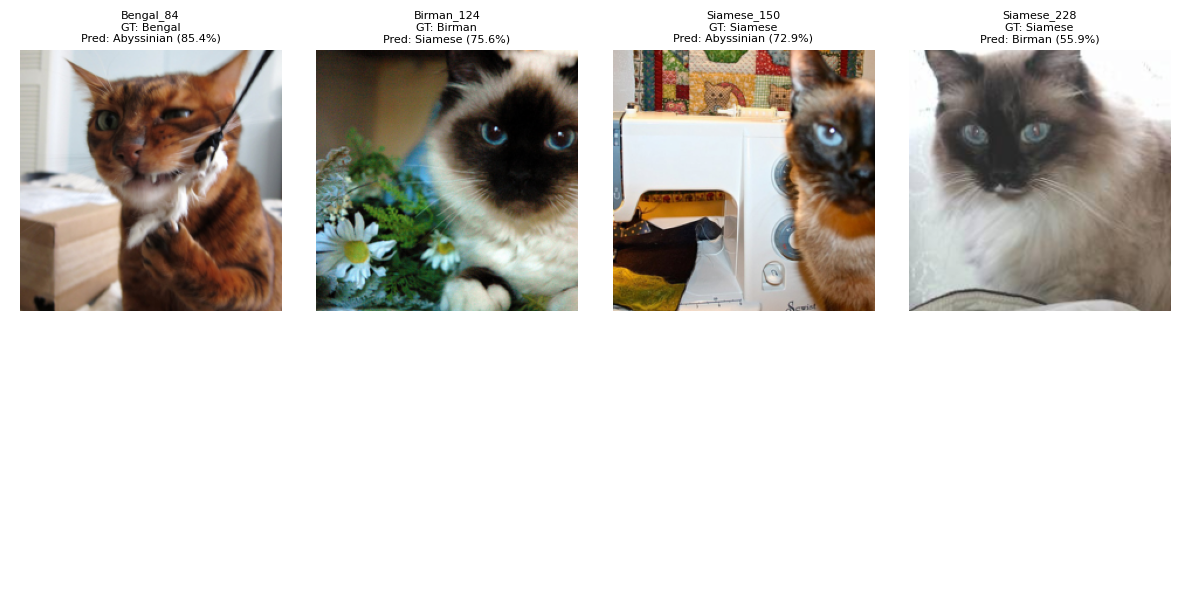

In [15]:
experiments = ["B1", "B2", "B3", "B4_noaug", "B5"]

fig, axes = plt.subplots(2, 3, figsize=(12, 6))
axes = axes.flatten()

for index, name in enumerate(experiments):
    history = pd.read_csv(f"hasil/{name}_history.csv")
    ax = axes[index]

    ax.plot(
        history["epoch"],
        history["train_loss"],
        label="Train"
    )
    ax.plot(
        history["epoch"],
        history["val_loss"],
        label="Validation"
    )

    ax.set_title(name)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()

axes[5].axis("off")

fig.tight_layout()
fig.savefig("hasil/loss.png", dpi=180)
plt.show()

print("Failure analysis model:", best_name)

table = predictions[best_name]

wrong = table[table["actual"] != table["predicted"]]
wrong = wrong.sort_values("confidence", ascending=False)
wrong = wrong.head(8).copy()

wrong["hipotesis"] = ""
wrong.to_csv("hasil/failure_analysis.csv", index=False)

display(wrong.drop(columns="path"))

if len(wrong) == 0:
    print("Tidak ada salah prediksi pada test set.")
else:
    fig, axes = plt.subplots(2, 4, figsize=(12, 6))
    axes = axes.flatten()

    for ax in axes:
        ax.axis("off")

    for index, row in enumerate(wrong.itertuples()):
        with Image.open(row.path) as image:
            image = image.convert("RGB")
            image = eval_transform(image)

        image = image.permute(1, 2, 0).numpy()
        image = image * np.array(std) + np.array(mean)
        image = np.clip(image, 0, 1)

        axes[index].imshow(image)
        axes[index].set_title(
            f"{row.id}\n"
            f"GT: {row.actual}\n"
            f"Pred: {row.predicted} ({row.confidence:.1%})",
            fontsize=8
        )

    fig.tight_layout()
    fig.savefig("hasil/kesalahan.png", dpi=180)
    plt.show()

In [16]:
for name, table in predictions.items():
    wrong_count = (table["actual"] != table["predicted"]).sum()
    print(name, ":", wrong_count, "salah dari", len(table), "gambar")

table = predictions[best_name]
all_wrong = table[table["actual"] != table["predicted"]]

print("\nModel terbaik:", best_name)
display(all_wrong[["id", "actual", "predicted", "confidence"]])

B1 : 144 salah dari 300 gambar
B2 : 7 salah dari 300 gambar
B3 : 4 salah dari 300 gambar
B4_noaug : 8 salah dari 300 gambar
B5 : 4 salah dari 300 gambar

Model terbaik: B5


,id,actual,predicted,confidence
195,Siamese_228,Siamese,Birman,0.559195
242,Siamese_150,Siamese,Abyssinian,0.728806
280,Bengal_84,Bengal,Abyssinian,0.853797
281,Birman_124,Birman,Siamese,0.755705


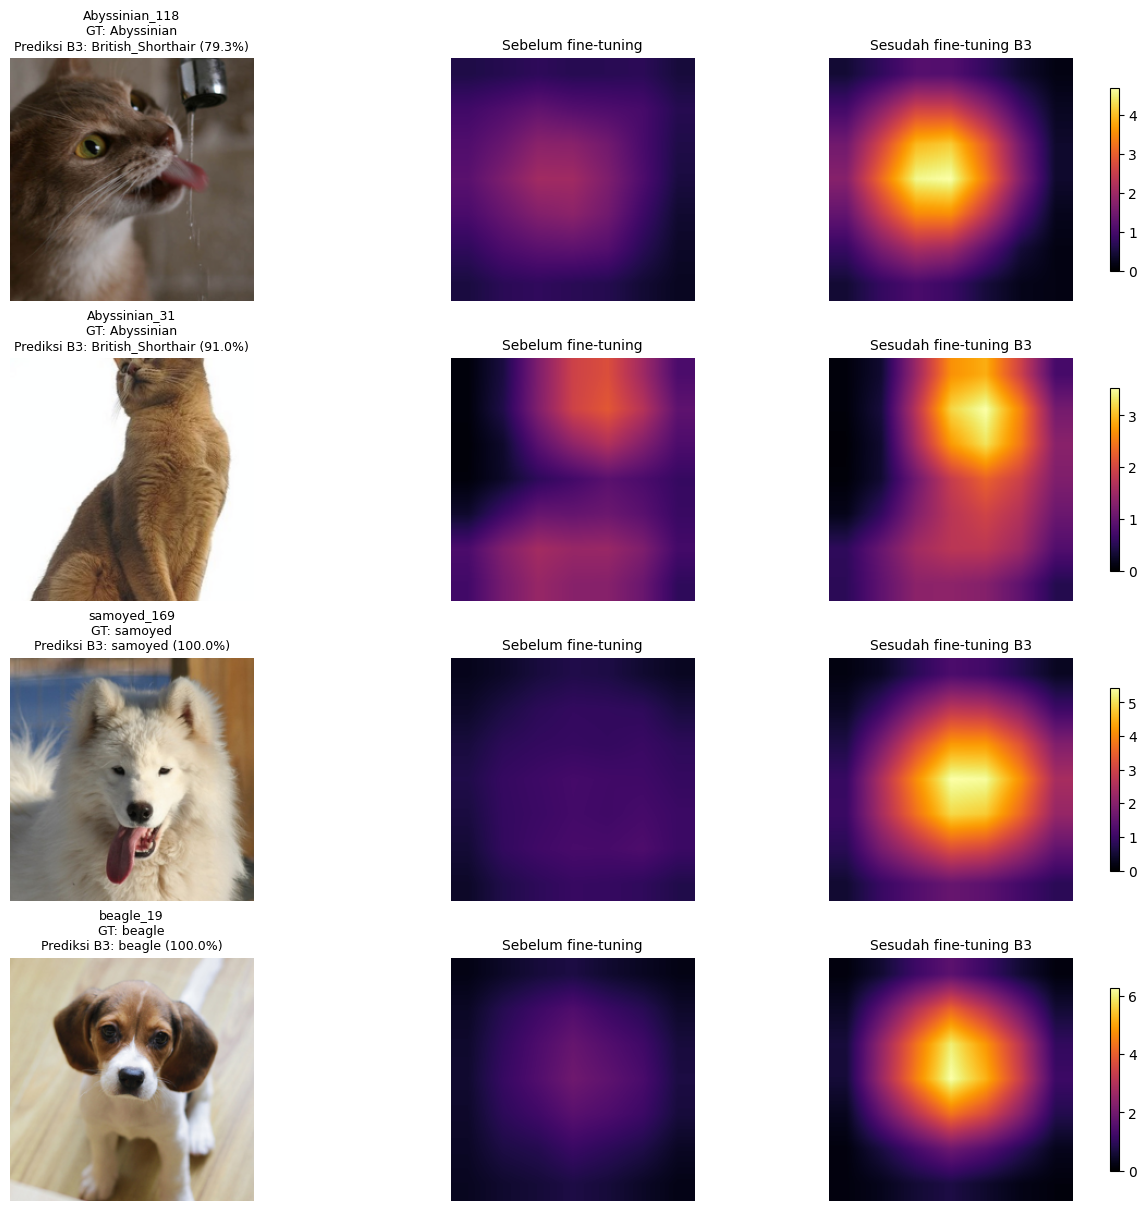

Tersimpan: hasil/C5_feature_maps.png
Tersimpan: hasil/C5_samples.csv
Warna terang menunjukkan rata-rata aktivasi lebih tinggi.
Skala warna sama untuk pasangan sebelum/sesudah tiap gambar.


In [17]:
#C5

import copy
import torch.nn.functional as F

# SEBELUM fine-tuning: ResNet-18 pretrained ImageNet
before = models.resnet18(
    weights=models.ResNet18_Weights.IMAGENET1K_V1
).cpu().eval()

# SESUDAH fine-tuning: checkpoint terbaik B3 yang sudah dilatih
after = copy.deepcopy(trained["B3"]).cpu().eval()

# Ambil 2 gambar salah dan 2 gambar benar dari hasil test B3
b3_table = predictions["B3"]

wrong_b3 = b3_table[
    b3_table["actual"] != b3_table["predicted"]
].sort_values("id").head(2)

correct_b3 = b3_table[
    b3_table["actual"] == b3_table["predicted"]
].sort_values("id")

correct_b3 = correct_b3.sample(
    n=min(2, len(correct_b3)),
    random_state=42
)

samples_c5 = pd.concat(
    [wrong_b3, correct_b3],
    ignore_index=True
)


@torch.no_grad()
def get_layer4_map(model, image_tensor):
    # Jalankan backbone sampai layer4
    features = model.conv1(image_tensor)
    features = model.bn1(features)
    features = model.relu(features)
    features = model.maxpool(features)

    features = model.layer1(features)
    features = model.layer2(features)
    features = model.layer3(features)
    features = model.layer4(features)

    # Rata-rata aktivasi seluruh channel
    activation = features.mean(dim=1, keepdim=True)

    # Perbesar peta aktivasi ke ukuran input
    activation = F.interpolate(
        activation,
        size=image_tensor.shape[-2:],
        mode="bilinear",
        align_corners=False
    )

    return activation[0, 0].numpy()


fig, axes = plt.subplots(
    len(samples_c5),
    3,
    figsize=(12, 3 * len(samples_c5)),
    squeeze=False,
    constrained_layout=True
)

for i, row in enumerate(samples_c5.itertuples(index=False)):
    with Image.open(row.path) as image:
        image_tensor = eval_transform(
            image.convert("RGB")
        ).unsqueeze(0).cpu()

    # Tampilkan input setelah preprocessing, tanpa normalisasi
    input_image = image_tensor[0].permute(1, 2, 0).numpy()
    input_image = input_image * np.array(std) + np.array(mean)
    input_image = np.clip(input_image, 0, 1)

    map_before = get_layer4_map(before, image_tensor)
    map_after = get_layer4_map(after, image_tensor)

    # Skala warna yang sama untuk pasangan sebelum/sesudah
    vmax = max(
        float(map_before.max()),
        float(map_after.max()),
        1e-8
    )

    axes[i, 0].imshow(input_image)
    axes[i, 0].set_title(
        f"{row.id}\n"
        f"GT: {row.actual}\n"
        f"Prediksi B3: {row.predicted} ({row.confidence:.1%})",
        fontsize=9
    )

    axes[i, 1].imshow(
        map_before,
        cmap="inferno",
        vmin=0,
        vmax=vmax
    )
    axes[i, 1].set_title("Sebelum fine-tuning", fontsize=10)

    heatmap = axes[i, 2].imshow(
        map_after,
        cmap="inferno",
        vmin=0,
        vmax=vmax
    )
    axes[i, 2].set_title("Sesudah fine-tuning B3", fontsize=10)

    fig.colorbar(
        heatmap,
        ax=axes[i, 1:].tolist(),
        shrink=0.75
    )

    for ax in axes[i]:
        ax.axis("off")

fig.savefig(
    "hasil/C5_feature_maps.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

samples_c5.to_csv("hasil/C5_samples.csv", index=False)

print("Tersimpan: hasil/C5_feature_maps.png")
print("Tersimpan: hasil/C5_samples.csv")
print("Warna terang menunjukkan rata-rata aktivasi lebih tinggi.")
print("Skala warna sama untuk pasangan sebelum/sesudah tiap gambar.")